# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name: Eshwar Lal**
**Student ID: 023-24-0186**
**Section: F**
**GitHub: https://github.com/Eshwarlal-125/Machine_Learning_Course**
**Kaggle: https://www.kaggle.com/mreshwar**
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [10]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [11]:
# Task 1 — load spam.csv, inspect shape/head/class balance
spam = pd.read_csv("spam.csv", encoding="latin-1")
print("Shape of Spam: ", spam.shape)
print("head of Spam: ", spam.head())
print("Counts: ",spam["v1"].value_counts())
print("Percentage: ",spam["v1"].value_counts(normalize=True)*100)


Shape of Spam:  (5572, 5)
head of Spam:       v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  
Counts:  v1
ham     4825
spam     747
Name: count, dtype: int64
Percentage:  v1
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [12]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweet = pd.read_csv("Tweets.csv")
print("Shape of Tweet: ", tweet.shape)
print("Head of Tweet: ", tweet.head())
print("Counts: ", tweet["airline_sentiment"].value_counts())
print("Percentage: ", tweet["airline_sentiment"].value_counts(normalize=True)*100)

tweet = tweet[tweet["airline_sentiment"].isin(["positive","negative"])].copy()
print("Tweets after removing neutrals: ", tweet.shape[0])
print("Remaining Counts: ", tweet["airline_sentiment"].value_counts())
print("Remaining Percentage: ", tweet["airline_sentiment"].value_counts(normalize=True)*100)

Shape of Tweet:  (14640, 15)
Head of Tweet:               tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
0                    NaN     cairdin                 NaN      

**Answer 2 (Task A — spam):**
_The model predicts whether an SMS message is spam or ham (normal). It supports filtering unwanted messages and is a binary classification problem._

**Answer 2 (Task B — sentiment):**
_The model predicts whether an airline tweet expresses positive or negative sentiment. After removing neutral tweets, it becomes a binary classification problem._

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [13]:
# Task 3 — clean text
spam["v2"] = spam["v2"].fillna("").str.lower()

print("Cleaned messages:")
print(spam["v2"].head())

Cleaned messages:
0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: v2, dtype: object


In [14]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets

X = spam["v2"]
y = spam["v1"].map({"ham": 0, "spam": 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,  stratify=y)

vectorizer = CountVectorizer()

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training data shape:", X_train_vec.shape)
print("Testing data shape:", X_test_vec.shape)
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))
print("Example vocabulary:", vectorizer.get_feature_names_out()[:20])

Training data shape: (4457, 7701)
Testing data shape: (1115, 7701)
Vocabulary size: 7701
Example vocabulary: ['00' '000' '008704050406' '0089' '0121' '01223585236' '01223585334' '02'
 '0207' '02072069400' '02073162414' '02085076972' '021' '03' '04' '0430'
 '05' '050703' '0578' '06']


**Answer 4 (why fit on training data only):**
_The vectorizer must be fitted only on training data to prevent data leakage from the test set. The test data is transformed using the vocabulary learned from training data to ensure a fair evaluation of the model._

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy: 0.9839
Precision: 0.9645
Recall: 0.9128
F1-score: 0.9379


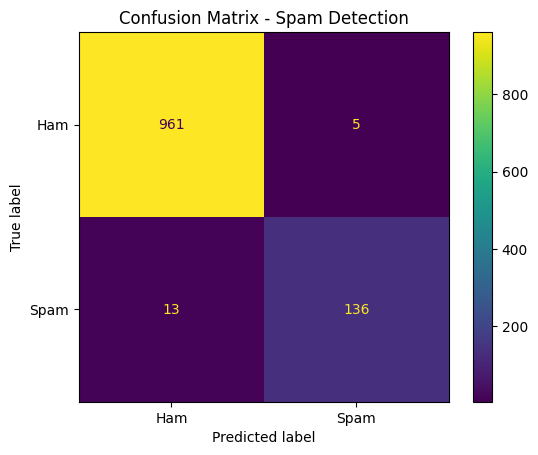

In [15]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix

model = MultinomialNB()
model.fit(X_train_vec, y_train)

y_pred = model.predict(X_test_vec)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

confusion_matrix = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix, display_labels=["Ham", "Spam"])
display.plot()
plt.title("Confusion Matrix - Spam Detection")
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9839 |
| Precision | 0.9645 |
| Recall | 0.9128 |
| F1-score | 0.9379 |

**Answer 6:**
_A false positive means a normal message is incorrectly classified as spam, while a false negative means spam reaches the inbox. A false positive may be worse because an important message could be hidden from the user. Therefore, I would prioritize precision to reduce false positives. However, if catching as much spam as possible is the main goal, I would prioritize recall._

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [16]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_

words = vectorizer.get_feature_names_out()

log_probs = model.feature_log_prob_

ham_probs = log_probs[0]
spam_probs = log_probs[1]

difference = spam_probs - ham_probs

top_spam_index = np.argsort(difference)[-15:][::-1]
top_spam_words = words[top_spam_index]

top_ham_index = np.argsort(difference)[:15]
top_ham_words = words[top_ham_index]

print("Top 15 Spam-associated words:")
print(top_spam_words)

print("\nTop 15 Ham-associated words:")
print(top_ham_words)

Top 15 Spam-associated words:
['claim' 'prize' '150p' 'tone' '18' 'cs' 'guaranteed' '500' '1000' 'uk'
 '150ppm' 'awarded' 'www' 'collection' 'rate']

Top 15 Ham-associated words:
['gt' 'lt' 'he' 'lor' 'da' 'she' 'later' 'ì_' 'll' 'doing' 'say' 'really'
 'ask' 'home' 'anything']


**Answer 7:**
_The words linked with spam mostly seem related to offers, prizes, and promotions, while the words linked with ham are more common in everyday conversations. This matches what I expected because spam messages often try to attract people with special offers, whereas normal messages are usually used to communicate with friends and family._

In [17]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations! You have won a free prize. Claim now",
    "Hey, are you coming to university today?",
    "URGENT! You have won a cash reward"
]
clean_messages = [
    msg.lower() for msg in my_messages
]
my_messages_vec = vectorizer.transform(clean_messages)
predictions = model.predict(my_messages_vec)
for msg, pred in zip(my_messages, predictions):
    label = "Spam" if pred == 1 else "Ham"
    print(f"Message: {msg}")
    print(f"Prediction: {label}\n")

Message: Congratulations! You have won a free prize. Claim now
Prediction: Spam

Message: Hey, are you coming to university today?
Prediction: Ham

Message: URGENT! You have won a cash reward
Prediction: Spam



**Answer 8:**
_The model correctly identifies most messages based on the words they contain. Messages with words like “prize” and “reward” are more likely to be classified as spam, while normal conversations are likely to be classified as ham. The results mostly match my expectations, although the model may sometimes make incorrect predictions._

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_https://www.kaggle.com/code/mreshwar/naive-bayes-spam-detection_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [18]:
# Task 11 — clean and vectorize the sentiment data (your own approach)

tweet = tweet.dropna(subset=["text", "airline_sentiment"]).copy()
tweet = tweet[tweet["airline_sentiment"].isin(["positive", "negative"])].copy()

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)  
    text = re.sub(r"@\w+", " ", text)              
    text = re.sub(r"#", "", text)
    return text.strip()

tweet["clean_text"] = tweet["text"].apply(clean_tweet)

X_tweet = tweet["clean_text"]
y_tweet = tweet["airline_sentiment"].map({
    "negative": 0,
    "positive": 1
})

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_tweet, y_tweet,
    test_size=0.2,
    random_state=42,
    stratify=y_tweet
)

tweet_vectorizer = CountVectorizer()
X_train_t_vec = tweet_vectorizer.fit_transform(X_train_t)
X_test_t_vec = tweet_vectorizer.transform(X_test_t)

print("Training shape:", X_train_t_vec.shape)
print("Testing shape:", X_test_t_vec.shape)
print("Vocabulary size:", len(tweet_vectorizer.get_feature_names_out()))


Training shape: (9232, 10087)
Testing shape: (2309, 10087)
Vocabulary size: 10087


**Answer 12:**
_Tweets contain links, @mentions, and hashtags, so I removed links and mentions but kept hashtag words because they may express sentiment. This helps the model focus on the meaningful words in each tweet._

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy: 0.9034
Precision: 0.9085
Recall: 0.5877
F1-score: 0.7137


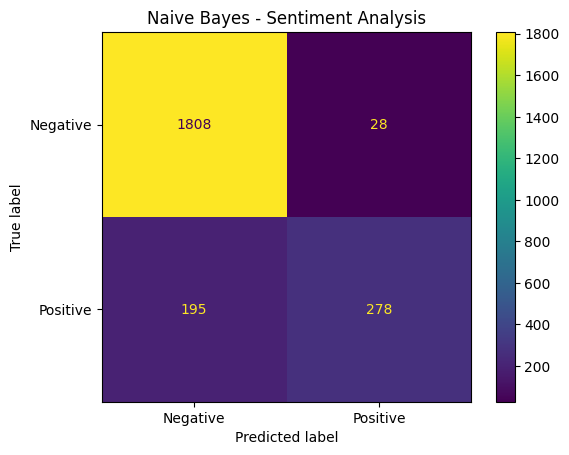

In [21]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
sentiment_model = MultinomialNB()
sentiment_model.fit(X_train_t_vec, y_train_t)

y_pred_t = sentiment_model.predict(X_test_t_vec)

accuracy_t = accuracy_score(y_test_t, y_pred_t)
precision_t = precision_score(y_test_t, y_pred_t, zero_division=0)
recall_t = recall_score(y_test_t, y_pred_t, zero_division=0)
f1_t = f1_score(y_test_t, y_pred_t, zero_division=0)

print("Accuracy:", round(accuracy_t, 4))
print("Precision:", round(precision_t, 4))
print("Recall:", round(recall_t, 4))
print("F1-score:", round(f1_t, 4))

cm_t = confusion_matrix(y_test_t, y_pred_t, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_t,
    display_labels=["Negative", "Positive"]
).plot()

plt.title("Naive Bayes - Sentiment Analysis")
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |  0.9034 |
| Precision | 0.9085 |
| Recall | 0.5877 |
| F1-score | 0.7137 |

*Naive Bayes may perform differently on sentiment analysis and spam detection because tweets often contain sarcasm, hashtags, and phrases where word meanings depend on context. Its assumption that words contribute independently is less suitable when words are related, such as “not good.” Spam messages may contain more obvious patterns, like promotional words, making them easier to classify. I will compare the actual F1-scores of both tasks to determine which performed better._

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_https://www.kaggle.com/code/mreshwar/naive-bayes-sentiment-analysis_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 0.9839 | 0.9034 |
| Precision | 0.9645 | 0.9085 |
| Recall | 0.9128 | 0.5877 |
| F1-score | 0.9379 | 0.7137 |

In [22]:
# Task 18 — train Logistic Regression on Task A's vectorized features

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)

lr_pred = lr_model.predict(X_test_vec)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, zero_division=0)
lr_recall = recall_score(y_test, lr_pred, zero_division=0)
lr_f1 = f1_score(y_test, lr_pred, zero_division=0)

print("Logistic Regression Accuracy:", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1-score:", round(lr_f1, 4))

print("\nNaive Bayes F1-score:", round(f1, 4))
print("Logistic Regression F1-score:", round(lr_f1, 4))

if lr_f1 > f1:
    print("Winner: Logistic Regression")
elif lr_f1 < f1:
    print("Winner: Naive Bayes")
else:
    print("Both models have equal F1-score")

Logistic Regression Accuracy: 0.9812
Precision: 0.9923
Recall: 0.8658
F1-score: 0.9247

Naive Bayes F1-score: 0.9379
Logistic Regression F1-score: 0.9247
Winner: Naive Bayes


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy |0.9856  | 0.9812 |
| Precision | 0.9918 | 0.9923 |
| Recall | 0.8889 | 0.8658 |
| F1-score | 0.9379 | 0.9247 |

**Answer 18 (which wins, and does it match expectations):**
_Naive Bayes performed slightly better than Logistic Regression because its F1-score was 0.9379 compared to 0.9247. This is reasonable for spam detection because certain words are strongly associated with spam messages. Logistic Regression also performed well, but Naive Bayes achieved the better F1-score on this dataset._

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
_Naive Bayes performed well on both spam detection and sentiment analysis, but it worked better for spam detection. I found that words related to offers and prizes were useful for identifying spam messages. I was surprised that Logistic Regression also achieved a high F1-score of 0.9247, although Naive Bayes performed slightly better with 0.9379. Tweets were more challenging because they contain mentions, hashtags, and phrases whose meanings depend on context. One limitation of Naive Bayes is that it treats words as independent, so it may struggle with phrases like “not good.” Overall, both models were useful, but their performance depended on the dataset and the type of text being classified._

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/mreshwar/naive-bayes-spam-detection
- Task B: https://www.kaggle.com/code/mreshwar/naive-bayes-sentiment-analysis

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted